In [3]:

import pandas as pd
import os

# Define city names
cities = [
    "delhi",
    "hyderabad",
    "bengaluru",
    "chennai",
    "mumbai",
    "pune"
]

base_path = r"D:\RouteRanker\data\processed"

for city in cities:
    file_path = os.path.join(
        base_path, city, "route_profile.csv"
    )

    df = pd.read_csv(file_path)

    print("\n", city.upper())
    print("Columns:", list(df.columns))
    print("Shape:", df.shape)



 DELHI
Columns: ['route_id', 'route_short_name', 'route_long_name', 'total_trips', 'total_stops']
Shape: (2403, 5)

 HYDERABAD
Columns: ['route_id', 'route_long_name', 'agency_id', 'route_type', 'total_trips', 'total_stops']
Shape: (1031, 6)

 BENGALURU
Columns: ['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'total_trips', 'total_stops']
Shape: (4434, 7)

 CHENNAI
Columns: ['route_id', 'route_short_name', 'route_long_name', 'route_type', 'agency_id', 'total_trips', 'total_stops']
Shape: (4611, 7)

 MUMBAI
Columns: ['route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_type', 'total_trips', 'total_stops']
Shape: (1609, 7)

 PUNE
Columns: ['route_id', 'agency_id', 'route_short_name', 'route_long_name', 'route_type', 'total_trips', 'total_stops']
Shape: (628, 7)


In [4]:

import pandas as pd
import os

base_path = r"D:\RouteRanker\data\processed"

all_city_data = []

for city in cities:
    file_path = os.path.join(
        base_path, city, "route_profile.csv"
    )

    df = pd.read_csv(file_path)

    df["city"] = city

    # Handle missing values
    df["total_trips"] = df["total_trips"].fillna(0)
    df["total_stops"] = df["total_stops"].fillna(0)

    if "route_type" not in df.columns:
        df["route_type"] = "Unknown"

    df["route_type"] = df["route_type"].fillna("Unknown")

    # Create frequency categories within each city
    rank = df["total_trips"].rank(pct=True)

    df["service_category"] = pd.cut(
        rank,
        bins=[0, 1/3, 2/3, 1],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )

    all_city_data.append(df)

classification_data = pd.concat(
    all_city_data, ignore_index=True
)

print("Combined dataset shape:", classification_data.shape)

print("\nService category distribution:")
print(classification_data["service_category"].value_counts())

print("\nDataset preview:")
display(classification_data[
    ["city", "total_stops", "route_type", "service_category"]
].head(10))


Combined dataset shape: (14716, 9)

Service category distribution:
service_category
Medium    5281
High      4929
Low       4506
Name: count, dtype: int64

Dataset preview:


,city,total_stops,route_type,service_category
0,delhi,25.0,Unknown,Medium
1,delhi,75.0,Unknown,Medium
2,delhi,94.0,Unknown,Medium
3,delhi,43.0,Unknown,Medium
4,delhi,31.0,Unknown,Medium
5,delhi,41.0,Unknown,High
6,delhi,21.0,Unknown,High
7,delhi,11.0,Unknown,High
8,delhi,26.0,Unknown,High
9,delhi,16.0,Unknown,Low


In [5]:
from sklearn.model_selection import train_test_split

# Select input features (do not include total_trips)
X = classification_data[
    ["city", "route_type", "total_stops"]
]

# Target category
y = classification_data["service_category"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training data: (11772, 3)
Testing data: (2944, 3)

Training category distribution:
service_category
Medium    4224
High      3943
Low       3605
Name: count, dtype: int64

Testing category distribution:
service_category
Medium    1057
High       986
Low        901
Name: count, dtype: int64


In [7]:
# Convert categorical columns to strings
X_train = X_train.copy()
X_test = X_test.copy()

X_train["city"] = X_train["city"].astype(str)
X_test["city"] = X_test["city"].astype(str)

X_train["route_type"] = X_train["route_type"].astype(str)
X_test["route_type"] = X_test["route_type"].astype(str)

# Train Random Forest again
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


RANDOM FOREST EVALUATION
------------------------
Accuracy: 0.49728260869565216
Precision: 0.5004252633727141
Recall: 0.49728260869565216
F1 Score: 0.49681705482304256

Classification Report:
              precision    recall  f1-score   support

        High       0.44      0.52      0.48       986
         Low       0.57      0.57      0.57       901
      Medium       0.49      0.42      0.45      1057

    accuracy                           0.50      2944
   macro avg       0.50      0.50      0.50      2944
weighted avg       0.50      0.50      0.50      2944



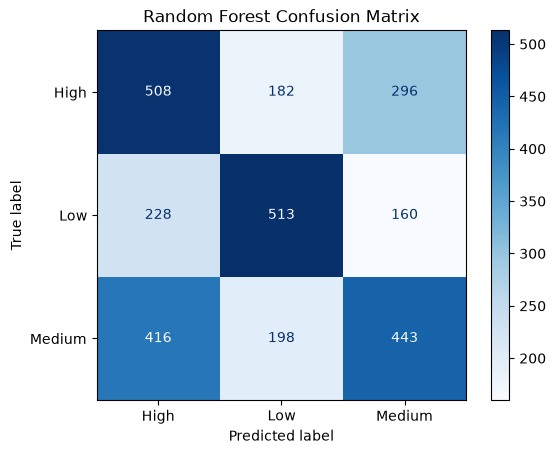

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict test data
rf_predictions = rf_model.predict(X_test)

# Evaluation metrics
print("RANDOM FOREST EVALUATION")
print("------------------------")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(
    y_test, rf_predictions, average="weighted"
))
print("Recall:", recall_score(
    y_test, rf_predictions, average="weighted"
))
print("F1 Score:", f1_score(
    y_test, rf_predictions, average="weighted"
))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["High", "Low", "Medium"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [9]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 7.4 MB/s eta 0:00:07
   -- ------------------------------------- 3.1/48.9 MB 8.2 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/48.9 MB 8.5 MB/s eta 0:00:06
   ----- ---------------------------------- 6.8/48.9 MB 8.5 MB/s eta 0:00:05
   ------- -------------------------------- 8.7/48.9 MB 8.6 MB/s eta 0:00:05
   -------- ------------------------------- 10.7/48.9 MB 8.7 MB/s eta 0:00:05
   ---------- ----------------------------- 12.6/48.9 MB 8.8 MB/s eta 0:00:05
   ------------ --------------------------- 14.9/48.9 MB 9.1 MB/s eta 0:00:04
   ------------- -------------------------- 17.0/48.9 MB 9.2 MB/s eta 0:00:04
   --------------- ------------------------ 19.4/48.9 MB 9.4 MB/s eta 0:00:04
   ----------------- ---------------------- 21.5/48.9 MB 9.6 MB/s eta 0:00:03
   ------------------- -------------------- 23.9/48.9 MB 9.7 MB/s eta 0:00:03


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from xgboost import XGBClassifier

# Convert target labels into numeric values
label_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

y_train_encoded = y_train.map(label_mapping)
y_test_encoded = y_test.map(label_mapping)

# Create XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42
    ))
])

# Train model
xgb_model.fit(X_train, y_train_encoded)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


XGBOOST EVALUATION
-------------------
Accuracy: 0.5180027173913043
Precision: 0.5250310060753728
Recall: 0.5180027173913043
F1 Score: 0.5189731475522452

Classification Report:
              precision    recall  f1-score   support

         Low       0.63      0.56      0.59       901
      Medium       0.50      0.45      0.47      1057
        High       0.46      0.55      0.50       986

    accuracy                           0.52      2944
   macro avg       0.53      0.52      0.52      2944
weighted avg       0.53      0.52      0.52      2944



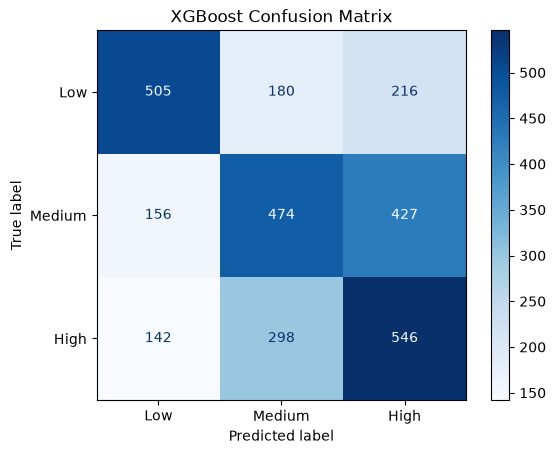

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict test data
xgb_predictions = xgb_model.predict(X_test)

# Evaluation metrics
print("XGBOOST EVALUATION")
print("-------------------")

print("Accuracy:", accuracy_score(y_test_encoded, xgb_predictions))
print("Precision:", precision_score(
    y_test_encoded, xgb_predictions, average="weighted"
))
print("Recall:", recall_score(
    y_test_encoded, xgb_predictions, average="weighted"
))
print("F1 Score:", f1_score(
    y_test_encoded, xgb_predictions, average="weighted"
))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    xgb_predictions,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"]
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    xgb_predictions,
    labels=[0, 1, 2],
    display_labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [12]:
import os
import joblib
import pandas as pd

# Create Module 6 model folder
model_path = r"D:\RouteRanker\data\model_results"
os.makedirs(model_path, exist_ok=True)

# Save trained models
joblib.dump(
    rf_model,
    os.path.join(model_path, "random_forest_model.joblib")
)

joblib.dump(
    xgb_model,
    os.path.join(model_path, "xgboost_model.joblib")
)

# Save classification comparison
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [0.4972826, 0.5180027],
    "Precision": [0.5004253, 0.5250310],
    "Recall": [0.4972826, 0.5180027],
    "F1_Score": [0.4968171, 0.5189731]
})

comparison.to_csv(
    os.path.join(model_path, "classification_comparison.csv"),
    index=False
)

print("Models and comparison results saved successfully!")
display(comparison)

Models and comparison results saved successfully!


,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.497283,0.500425,0.497283,0.496817
1,XGBoost,0.518003,0.525031,0.518003,0.518973


In [13]:
# Create test prediction results
classification_results = X_test.copy()

classification_results["Actual_Category"] = y_test.values

classification_results["RandomForest_Prediction"] = (
    rf_predictions
)

classification_results["XGBoost_Prediction"] = [
    {0: "Low", 1: "Medium", 2: "High"}[value]
    for value in xgb_predictions
]

# Save results
output_file = os.path.join(
    model_path,
    "classification_predictions.csv"
)

classification_results.to_csv(output_file, index=False)

print("Classification predictions saved successfully!")
print("Total test predictions:", len(classification_results))

display(classification_results.head(10))

Classification predictions saved successfully!
Total test predictions: 2944


,city,route_type,total_stops,Actual_Category,RandomForest_Prediction,XGBoost_Prediction
1596,delhi,Unknown,36.0,High,Medium,Medium
3593,bengaluru,3,0.0,Low,Low,Low
9548,chennai,3,6.0,Medium,Low,Medium
6395,bengaluru,3,84.0,Medium,Medium,Medium
3474,bengaluru,3,80.0,High,Medium,Medium
12323,chennai,3,3.0,Medium,Medium,Medium
11324,chennai,3,16.0,Medium,High,Medium
3298,hyderabad,3,28.0,Low,Low,Low
2393,delhi,Unknown,56.0,Medium,Low,High
2666,hyderabad,3,31.0,Low,Low,Low


In [15]:
processed_path = r"D:\RouteRanker\data\model_ready"
model_path = r"D:\RouteRanker\data\model_results"

print("Paths configured successfully!")

Paths configured successfully!


In [17]:
import joblib
import os

kmeans_models = joblib.load(
    os.path.join(model_path, "kmeans_models.joblib")
)

print("K-Means models loaded successfully!")
print("Available models:", list(kmeans_models.keys()))

K-Means models loaded successfully!
Available models: ['delhi', 'hyderabad', 'bengaluru', 'chennai', 'mumbai', 'pune']


In [18]:
import os
import pandas as pd

cities = [
    "delhi", "hyderabad", "bengaluru",
    "chennai", "mumbai", "pune"
]

inference_path = r"D:\RouteRanker\data\inference"
os.makedirs(inference_path, exist_ok=True)

kmeans_results = []

for city in cities:

    # Load processed route data
    file_path = os.path.join(
        processed_path, f"{city}_processed.csv"
    )

    df = pd.read_csv(file_path)

    # Use the same scaled features as Module 5
    features = df[
        ["total_trips_scaled", "total_stops_scaled"]
    ]

    # Apply saved K-Means model
    model = kmeans_models[city]
    df["KMeans_Inference_Cluster"] = model.predict(features)

    # Save inference result separately
    output_file = os.path.join(
        inference_path, f"{city}_kmeans_inference.csv"
    )

    df.to_csv(output_file, index=False)

    kmeans_results.append({
        "City": city,
        "Total Routes": len(df),
        "Clusters Assigned": df["KMeans_Inference_Cluster"].nunique()
    })

print("K-Means inference completed!")

display(pd.DataFrame(kmeans_results))

K-Means inference completed!


,City,Total Routes,Clusters Assigned
0,delhi,2403,2
1,hyderabad,1031,2
2,bengaluru,4434,2
3,chennai,4611,3
4,mumbai,1609,3
5,pune,628,3


In [19]:
import joblib
import numpy as np
import pandas as pd
import os
from sklearn.metrics import pairwise_distances

# Load saved DBSCAN models
dbscan_models = joblib.load(
    os.path.join(model_path, "dbscan_models.joblib")
)

# Original eps values from Module 5
eps_values = {
    "delhi": 0.3,
    "hyderabad": 0.3,
    "bengaluru": 0.5,
    "chennai": 0.7,
    "mumbai": 0.5,
    "pune": 0.3
}

dbscan_results = []

for city in cities:

    df = pd.read_csv(
        os.path.join(processed_path, f"{city}_processed.csv")
    )

    features = df[
        ["total_trips_scaled", "total_stops_scaled"]
    ].values

    model = dbscan_models[city]

    core_points = model.components_
    core_labels = model.labels_[model.core_sample_indices_]

    distances = pairwise_distances(features, core_points)

    nearest = distances.argmin(axis=1)
    minimum_distances = distances.min(axis=1)

    predictions = np.where(
        minimum_distances <= eps_values[city],
        core_labels[nearest],
        -1
    )

    df["DBSCAN_Inference_Cluster"] = predictions

    df.to_csv(
        os.path.join(inference_path, f"{city}_dbscan_inference.csv"),
        index=False
    )

    dbscan_results.append({
        "City": city,
        "Total Routes": len(df),
        "Clusters Assigned": len(set(predictions) - {-1}),
        "Unassigned Routes": int((predictions == -1).sum())
    })

print("DBSCAN inference completed!")

display(pd.DataFrame(dbscan_results))

DBSCAN inference completed!


,City,Total Routes,Clusters Assigned,Unassigned Routes
0,delhi,2403,3,56
1,hyderabad,1031,2,51
2,bengaluru,4434,3,29
3,chennai,4611,3,1
4,mumbai,1609,2,10
5,pune,628,2,27


In [20]:
import pandas as pd
import os

unusual_routes = []

for city in cities:

    file_path = os.path.join(
        inference_path, f"{city}_dbscan_inference.csv"
    )

    df = pd.read_csv(file_path)

    unusual = df[
        df["DBSCAN_Inference_Cluster"] == -1
    ].copy()

    unusual["City"] = city
    unusual_routes.append(unusual)

# Combine all cities
unusual_routes_df = pd.concat(
    unusual_routes, ignore_index=True
)

# Save results
unusual_routes_df.to_csv(
    os.path.join(inference_path, "unusual_routes.csv"),
    index=False
)

print("Unusual route analysis completed!")
print("Total unassigned routes:", len(unusual_routes_df))

display(
    unusual_routes_df[
        ["City", "route_id", "total_trips", "total_stops"]
    ].head(10)
)

Unusual route analysis completed!
Total unassigned routes: 174


,City,route_id,total_trips,total_stops
0,delhi,362,16.0,94.0
1,delhi,1365,22.0,94.0
2,delhi,1872,9.0,92.0
3,delhi,1185,171.0,9.0
4,delhi,10423,35.0,176.0
5,delhi,10040,12.0,196.0
6,delhi,1008,146.0,16.0
7,delhi,612,118.0,84.0
8,delhi,1239,176.0,9.0
9,delhi,375,211.0,25.0


In [21]:
import pandas as pd
import os

suggestions = []

for city in cities:

    file_path = os.path.join(
        inference_path, f"{city}_dbscan_inference.csv"
    )

    df = pd.read_csv(file_path)

    # Calculate city-specific limits
    trips_low = df["total_trips"].quantile(0.05)
    trips_high = df["total_trips"].quantile(0.95)

    stops_low = df["total_stops"].quantile(0.05)
    stops_high = df["total_stops"].quantile(0.95)

    unusual = df[df["DBSCAN_Inference_Cluster"] == -1].copy()

    for _, row in unusual.iterrows():

        reasons = []

        if row["total_trips"] <= trips_low:
            reasons.append("Very low scheduled trips")

        if row["total_trips"] >= trips_high:
            reasons.append("Very high scheduled trips")

        if row["total_stops"] <= stops_low:
            reasons.append("Very low stop count")

        if row["total_stops"] >= stops_high:
            reasons.append("Very high stop count")

        if not reasons:
            reasons.append("Unusual DBSCAN cluster position")

        suggestions.append({
            "City": city,
            "Route_ID": row["route_id"],
            "Total_Trips": row["total_trips"],
            "Total_Stops": row["total_stops"],
            "Review_Reason": ", ".join(reasons),
            "Suggested_Action": "Review route schedule and GTFS data"
        })

suggestions_df = pd.DataFrame(suggestions)

suggestions_df.to_csv(
    os.path.join(inference_path, "route_review_suggestions.csv"),
    index=False
)

print("Route review suggestions generated!")
print("Total routes:", len(suggestions_df))

display(suggestions_df.head(10))

Route review suggestions generated!
Total routes: 174


,City,Route_ID,Total_Trips,Total_Stops,Review_Reason,Suggested_Action
0,delhi,362.0,16.0,94.0,Very high stop count,Review route schedule and GTFS data
1,delhi,1365.0,22.0,94.0,Very high stop count,Review route schedule and GTFS data
2,delhi,1872.0,9.0,92.0,Very high stop count,Review route schedule and GTFS data
3,delhi,1185.0,171.0,9.0,"Very high scheduled trips, Very low stop count",Review route schedule and GTFS data
4,delhi,10423.0,35.0,176.0,Very high stop count,Review route schedule and GTFS data
5,delhi,10040.0,12.0,196.0,Very high stop count,Review route schedule and GTFS data
6,delhi,1008.0,146.0,16.0,Very high scheduled trips,Review route schedule and GTFS data
7,delhi,612.0,118.0,84.0,Very high stop count,Review route schedule and GTFS data
8,delhi,1239.0,176.0,9.0,"Very high scheduled trips, Very low stop count",Review route schedule and GTFS data
9,delhi,375.0,211.0,25.0,Very high scheduled trips,Review route schedule and GTFS data


In [22]:
import pandas as pd
import os
import numpy as np

simulation_results = []

for city in cities:

    file_path = os.path.join(
        inference_path, f"{city}_dbscan_inference.csv"
    )

    df = pd.read_csv(file_path)

    # Preserve original scheduled trips
    df["Original_Trips"] = df["total_trips"]

    # Identify routes flagged for very high scheduled trips
    city_suggestions = suggestions_df[
        suggestions_df["City"] == city
    ]

    high_trip_ids = city_suggestions[
        city_suggestions["Review_Reason"].str.contains(
            "Very high scheduled trips"
        )
    ]["Route_ID"].astype(str)

    # Apply a hypothetical 10% reduction
    df["Simulated_Trips"] = df["total_trips"]

    mask = (
        df["route_id"].astype(str).isin(high_trip_ids)
    )

    df.loc[mask, "Simulated_Trips"] = np.floor(
        df.loc[mask, "total_trips"] * 0.90
    )

    # Save separate simulated city dataset
    df.to_csv(
        os.path.join(inference_path, f"{city}_simulated_routes.csv"),
        index=False
    )

    simulation_results.append({
        "City": city,
        "Original_Routes": len(df),
        "Simulated_Routes": len(df),
        "Original_Scheduled_Trips": df["Original_Trips"].sum(),
        "Simulated_Scheduled_Trips": df["Simulated_Trips"].sum()
    })

simulation_df = pd.DataFrame(simulation_results)

simulation_df.to_csv(
    os.path.join(inference_path, "simulation_comparison.csv"),
    index=False
)

print("Simulation completed!")
display(simulation_df)

Simulation completed!


,City,Original_Routes,Simulated_Routes,Original_Scheduled_Trips,Simulated_Scheduled_Trips
0,delhi,2403,2403,89393.0,89393.0
1,hyderabad,1031,1031,44892.0,42959.0
2,bengaluru,4434,4434,57836.0,57836.0
3,chennai,4611,4611,47047.0,47047.0
4,mumbai,1609,1609,99080.0,98947.0
5,pune,628,628,10128.0,10128.0


In [23]:
for city in cities:
    file_path = os.path.join(
        inference_path, f"{city}_simulated_routes.csv"
    )

    df = pd.read_csv(file_path)

    print(
        city,
        "| Original missing:", df["Original_Trips"].isna().sum(),
        "| Simulated missing:", df["Simulated_Trips"].isna().sum(),
        "| Simulated total:", df["Simulated_Trips"].sum()
    )

delhi | Original missing: 0 | Simulated missing: 0 | Simulated total: 89393
hyderabad | Original missing: 0 | Simulated missing: 0 | Simulated total: 42959
bengaluru | Original missing: 0 | Simulated missing: 0 | Simulated total: 57836.0
chennai | Original missing: 0 | Simulated missing: 0 | Simulated total: 47047.0
mumbai | Original missing: 0 | Simulated missing: 0 | Simulated total: 98947.0
pune | Original missing: 0 | Simulated missing: 0 | Simulated total: 10128


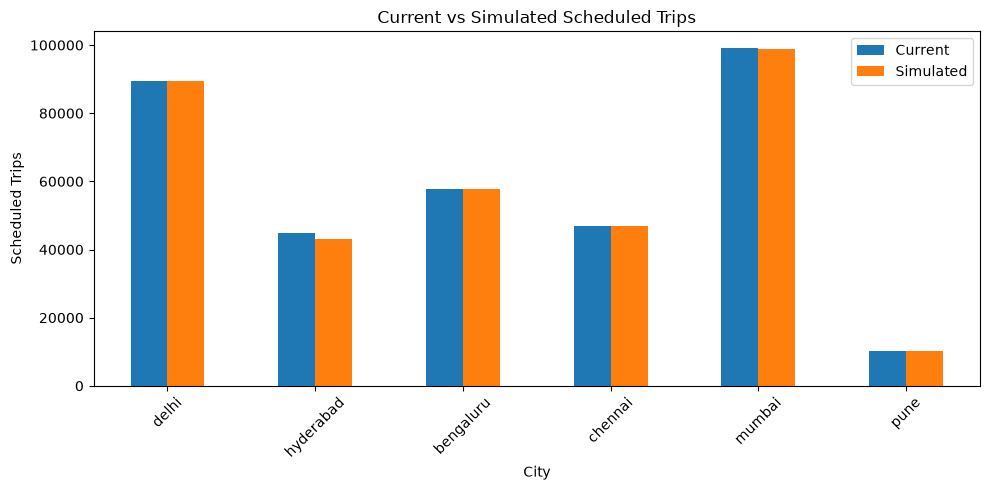

Comparison chart saved successfully!


In [24]:
import matplotlib.pyplot as plt

simulation_df = pd.read_csv(
    os.path.join(inference_path, "simulation_comparison.csv")
)

simulation_df.set_index("City")[
    ["Original_Scheduled_Trips", "Simulated_Scheduled_Trips"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Current vs Simulated Scheduled Trips")
plt.xlabel("City")
plt.ylabel("Scheduled Trips")
plt.xticks(rotation=45)
plt.legend(["Current", "Simulated"])
plt.tight_layout()

plt.savefig(
    os.path.join(inference_path, "simulation_comparison.png")
)

plt.show()

print("Comparison chart saved successfully!")

In [25]:
import os

report_path = r"D:\RouteRanker\reports"
os.makedirs(report_path, exist_ok=True)

report = f"""
# Module 6: Model Inference and Route Optimization

## 1. Objective
To apply trained machine learning models, identify unusual routes,
generate route review suggestions and simulate possible schedule changes.

## 2. Classification Models
Two classification models were trained:
- Random Forest
- XGBoost

Classification results:

{comparison.to_string(index=False)}

The categories Low, Medium and High were derived from scheduled trip
frequency within each city. These are proxy labels, not independently
verified ground-truth labels or passenger-demand categories.

## 3. K-Means Inference
Saved K-Means models were applied to six cities.

{pd.DataFrame(kmeans_results).to_string(index=False)}

## 4. DBSCAN Inference
Saved DBSCAN models were applied using their core points and eps values.

{pd.DataFrame(dbscan_results).to_string(index=False)}

Unassigned routes require further investigation. They are not automatically
inefficient routes.

## 5. Unusual Route Analysis
A total of {len(unusual_routes_df)} routes were identified as unassigned
by DBSCAN.

Route review suggestions were generated using scheduled trip counts
and stop counts.

## 6. Route Optimization Simulation
A hypothetical 10% scheduled-trip reduction was applied to selected
routes flagged for very high scheduled frequency.

{simulation_df.to_string(index=False)}

This is an illustrative simulation, not a real operational recommendation.
Route merging, splitting and service reductions require further evidence
such as geographical overlap, passenger demand and service coverage.

## 7. Limitations
- GTFS data represents scheduled services, not actual passenger counts.
- No independently verified classification labels were available.
- No actual overcrowding information was available.
- DBSCAN unassigned routes are not necessarily inefficient.
- The simulation does not prove an improvement in service quality.
- Geographical connectivity and passenger demand require further analysis.

## 8. Conclusion
Module 6 demonstrated classification, model inference, unusual route
identification, route review suggestions and hypothetical schedule
simulation across six Indian cities.
"""

with open(
    os.path.join(report_path, "Module6_Report.md"),
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Module 6 report created successfully!")
print(os.path.join(report_path, "Module6_Report.md"))

Module 6 report created successfully!
D:\RouteRanker\reports\Module6_Report.md


In [26]:
import os

model_path = r"D:\RouteRanker\data\model_results"

print("SAVED MODEL AND PREPROCESSING FILES")
print("-----------------------------------")

for file in os.listdir(model_path):
    print(file)

SAVED MODEL AND PREPROCESSING FILES
-----------------------------------
bengaluru_clustered_routes.csv
chennai_clustered_routes.csv
classification_comparison.csv
classification_predictions.csv
clustering_comparison.csv
dbscan_evaluation.csv
dbscan_models.joblib
dbscan_parameter_experiments.csv
delhi_clustered_routes.csv
hyderabad_clustered_routes.csv
kmeans_evaluation.csv
kmeans_models.joblib
mumbai_clustered_routes.csv
pune_clustered_routes.csv
random_forest_model.joblib
xgboost_model.joblib


In [27]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

scalers = {}
processed_path = r"D:\RouteRanker\data\model_ready"

for city in cities:

    df = pd.read_csv(
        os.path.join(processed_path, f"{city}_processed.csv")
    )

    original_features = df[
        ["total_trips", "total_stops"]
    ]

    saved_scaled = df[
        ["total_trips_scaled", "total_stops_scaled"]
    ].values

    scaler = StandardScaler()
    recreated_scaled = scaler.fit_transform(original_features)

    # Verify against Module 4 scaled values
    matches = np.allclose(
        saved_scaled,
        recreated_scaled,
        atol=1e-5
    )

    print(city, "Scaling matches:", matches)

    if matches:
        scalers[city] = scaler

if len(scalers) == len(cities):
    joblib.dump(
        scalers,
        os.path.join(model_path, "city_scalers.joblib")
    )
    print("\nAll six preprocessing objects saved!")
else:
    print("\nSome scalers need further verification.")

delhi Scaling matches: True
hyderabad Scaling matches: True
bengaluru Scaling matches: True
chennai Scaling matches: True
mumbai Scaling matches: True
pune Scaling matches: True

All six preprocessing objects saved!


Tasks Completed
- Done
   Trained K-Means and DBSCAN models.
- Done
   Random Forest and XGBoost models.
- Done
   Six preprocessing objects.
- Done
   Cluster assignments and classification predictions.
- Done
   Unusual route analysis and review suggestions.
- Done
   Simulated datasets and comparison chart.

In [28]:
report_file = os.path.join(
    report_path, "Module6_Report.md"
)

with open(report_file, "a", encoding="utf-8") as file:
    file.write("""
## 9. Preprocessing Objects

Six city-specific StandardScaler objects were reconstructed
and verified against the scaled features from Module 4.

Verification results:
- Delhi: True
- Hyderabad: True
- Bengaluru: True
- Chennai: True
- Mumbai: True
- Pune: True

All six scaler objects were saved in:
data/model_results/city_scalers.joblib

## 10. Saved Model Files

- kmeans_models.joblib
- dbscan_models.joblib
- random_forest_model.joblib
- xgboost_model.joblib
- city_scalers.joblib

""")

print("Module 6 report updated successfully!")

Module 6 report updated successfully!
